# Tugas praktikum

## Tugas 1. Modifikasi CNN CIFAR-10

In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

2026-11-16 20:34:19.357747: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-16 20:34:19.358196: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-16 20:34:19.386776: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0

In [3]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.RandomFlip('horizontal'),
    layers.RandomTranslation(0.1, 0.1),

    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10)
])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 random_flip (RandomFlip)    (None, 32, 32, 3)         0         
                                                                 
 random_translation (Random  (None, 32, 32, 3)         0         
 Translation)                                                    
                                                                 
 conv2d (Conv2D)             (None, 32, 32, 32)        896       
                                                                 
 batch_normalization (Batch  (None, 32, 32, 32)        128       
 Normalization)                                                  
                                                                 
 activation (Activation)     (None, 32, 32, 32)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 32)        9

In [4]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [5]:
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=5, min_lr=0.00001)
history = model.fit(train_images, train_labels, epochs=40, batch_size=64,
                    validation_split=0.2, callbacks=[reduce_lr])

Epoch 1/40


2026-11-16 20:35:00.907962: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape insequential/dropout/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1794836106.803205   26045 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


625/625 [==============================] - 29s 25ms/step - loss: 2.0681 - accuracy: 0.2062 - val_loss: 1.9395 - val_accuracy: 0.2444 - lr: 0.0010
Epoch 2/40
625/625 [==============================] - 11s 18ms/step - loss: 1.7719 - accuracy: 0.3032 - val_loss: 1.5810 - val_accuracy: 0.4220 - lr: 0.0010
Epoch 3/40
625/625 [==============================] - 11s 18ms/step - loss: 1.6449 - accuracy: 0.3618 - val_loss: 1.6263 - val_accuracy: 0.3899 - lr: 0.0010
Epoch 4/40
625/625 [==============================] - 11s 17ms/step - loss: 1.5235 - accuracy: 0.4136 - val_loss: 1.1978 - val_accuracy: 0.5587 - lr: 0.0010
Epoch 5/40
625/625 [==============================] - 11s 18ms/step - loss: 1.4478 - accuracy: 0.4493 - val_loss: 1.5249 - val_accuracy: 0.4650 - lr: 0.0010
Epoch 6/40
625/625 [==============================] - 11s 18ms/step - loss: 1.3770 - accuracy: 0.4839 - val_loss: 1.2087 - val_accuracy: 0.5727 - lr: 0.0010
Epoch 7/40
625/625 [==============================] - 14s 22ms/step -

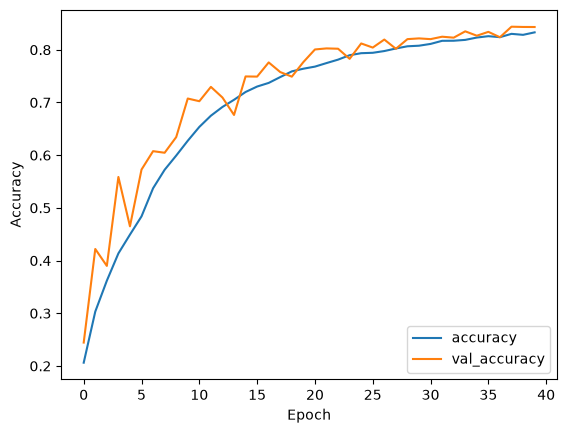

313/313 - 3s - loss: 0.5185 - accuracy: 0.8305 - 3s/epoch - 9ms/step
Akurasi testing CIFAR-10: 0.8305
Target lebih dari 80% tercapai: True


In [6]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f'Akurasi testing CIFAR-10: {test_acc:.4f}')
print('Target lebih dari 80% tercapai:', test_acc > 0.80)

## Tugas 2. CNN untuk klasifikasi MNIST

In [7]:
(train_images, train_labels), (test_images, test_labels) = datasets.mnist.load_data()
train_images = train_images.reshape(-1, 28, 28, 1) / 255.0
test_images = test_images.reshape(-1, 28, 28, 1) / 255.0

In [8]:
model_mnist = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10)
])
model_mnist.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_6 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 13, 13, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_7 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 flatten_1 (Flatten)         (None, 1600)              0         
                                                                 
 dense_2 (Dense)             (None, 64)               

In [9]:
model_mnist.compile(optimizer='adam',
                    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                    metrics=['accuracy'])
history_mnist = model_mnist.fit(train_images, train_labels, epochs=10,
                                validation_split=0.2)

Epoch 1/10
1500/1500 [==============================] - 12s 6ms/step - loss: 0.1639 - accuracy: 0.9508 - val_loss: 0.0675 - val_accuracy: 0.9792
Epoch 2/10
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0521 - accuracy: 0.9840 - val_loss: 0.0519 - val_accuracy: 0.9844
Epoch 3/10
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0364 - accuracy: 0.9889 - val_loss: 0.0397 - val_accuracy: 0.9883
Epoch 4/10
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0265 - accuracy: 0.9912 - val_loss: 0.0434 - val_accuracy: 0.9873
Epoch 5/10
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0202 - accuracy: 0.9932 - val_loss: 0.0337 - val_accuracy: 0.9912
Epoch 6/10
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0149 - accuracy: 0.9949 - val_loss: 0.0403 - val_accuracy: 0.9878
Epoch 7/10
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0106 - accuracy: 0.9962 - val_loss: 0.0452 - val_accuracy

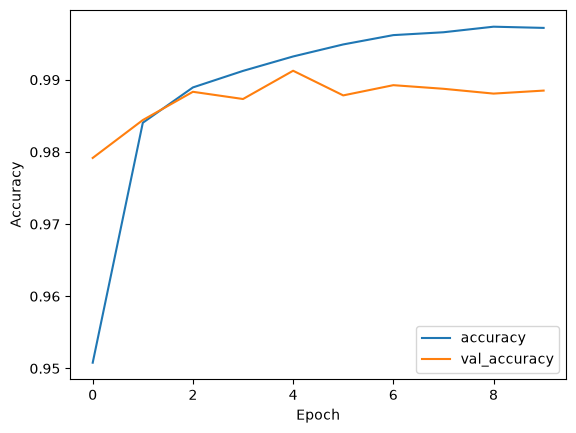

313/313 - 1s - loss: 0.0418 - accuracy: 0.9904 - 1s/epoch - 5ms/step
Akurasi testing MNIST: 0.9904


In [10]:
plt.plot(history_mnist.history['accuracy'], label='accuracy')
plt.plot(history_mnist.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.show()

mnist_loss, mnist_acc = model_mnist.evaluate(test_images, test_labels, verbose=2)
print(f'Akurasi testing MNIST: {mnist_acc:.4f}')